# ✂️ Отбор признаков

В этом ноутбуке разбираем, как отбирать информативные признаки и избавляться от шума так, чтобы:
- улучшить качество модели;
- уменьшить размерность данных и ускорить обучение;
- лучше понимать, **за счёт каких признаков** модель принимает решения.

Мы посмотрим на:
- простые статистические методы (корреляции, матрица φ<sub>K</sub> / Phik);
- методы важности признаков на основе моделей (`feature_importance`, permutation importance, SHAP);
- пошаговый отбор признаков (forward selection);
- встроенный отбор признаков в CatBoost (`select_features`).

По ходу ноутбука будут ссылки на документацию, чтобы можно было быстро углубиться в детали.


В данном уроке мы рассмотрим способы отобрать наиболее информативные признаки, избавиться от шумных, тем самым увеличив качество модели, а также снизив объем данных, поступаемый на вход.

Для этого урока подготовлен датасет с задачей оттока клиентов (churn) и **добавленным шумом** — лишними признаками, которые не помогают предсказывать таргет.

Наша цель в основной части ноутбука:
- построить baseline‑модель;
- сравнить разные подходы к отбору признаков;
- показать, как можно выделить более компактный и понятный набор признаков **без просадки качества** (а иногда даже с небольшим улучшением).

## Подготовка окружения и данных

In [5]:
# Устанавливаем дополнительные библиотеки
# !pip install -q phik catboost gdown

# Скачиваем и распаковываем данные для основного примера
# !wget -O 4_2_churn_feature_selection.rar \
#     https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_2/4_2_churn_feature_selection.rar
# !unrar x 4_2_churn_feature_selection.rar

In [6]:
import os
import requests

URL = 'https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_2/4_2_churn_feature_selection.rar'
FOLDER = 'content'
PATH = os.path.join(FOLDER, '4_2_churn_feature_selection.rar')

# Проверка наличия файла и скачивание по необходимости
if not os.path.exists(PATH):
    r = requests.get(URL)
    with open(PATH, 'wb') as f:
        f.write(r.content)
    print('Файл скачан:', PATH)
else:
    print('Файл уже скачан')

Файл скачан: content\4_2_churn_feature_selection.rar


In [7]:
import os
import patoolib

EXTRACT_FOLDER = 'content/4_2_churn_feature_selection'
PATH = os.path.join('content', '4_2_churn_feature_selection.rar')

if not os.path.exists(EXTRACT_FOLDER):
    patoolib.extract_archive(PATH, outdir=EXTRACT_FOLDER)
    print('Файл распакован в:', EXTRACT_FOLDER)
else:
    print('Файл уже распакован')

INFO patool: Extracting content\4_2_churn_feature_selection.rar ...
INFO patool: could not find a 'file' executable, falling back to guess mime type by file extension
INFO patool: ... creating output directory `content/4_2_churn_feature_selection'.
INFO patool: running "C:\Program Files\WinRAR\rar.EXE" x -kb -or -- c:\Projects\ds-stepik\ds_simulation\content\4_2_churn_feature_selection.rar
INFO patool: ... content\4_2_churn_feature_selection.rar extracted to `content/4_2_churn_feature_selection'.


Файл распакован в: content/4_2_churn_feature_selection


In [8]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

from catboost import CatBoostClassifier, Pool

import phik
from phik.report import plot_correlation_matrix

plt.style.use("seaborn-v0_8-whitegrid")

# Загружаем основной датасет
df = pd.read_csv("content/4_2_churn_feature_selection/4_2_churn_feature_selection.csv")
df.head()

,snapshot_month,client_id,n_contacts,n_success_calls,n_fail_calls,n_sms,n_emails,bal_min_30d,bal_max_30d,bal_avg_30d,...,noise_exp,noise_permuted,noise_permuted_risk,noise_interaction,noise_cluster_like,noise_sin_time,noise_random_walk,noise_smooth,noise_decay,noise_trend_spikes
0,2025-01-31,C012117,3,0,3,2,1,6600.697236,14846.931029,11849.483371,...,0.751195,47.998506,28.311769,0.000088,0,-0.017556,-0.000465,-0.025155,-1.477526,0.000138
1,2025-03-31,C025265,0,0,0,1,5,15039.135353,20601.690679,17355.702667,...,0.270397,54.979267,46.918911,0.010679,2,-0.007760,-0.001341,-0.666549,-0.934986,-0.001341
2,2025-09-30,C001057,2,1,1,1,1,9078.585701,15504.615792,12003.890555,...,31.898826,29.556711,18.853281,0.001366,2,0.081961,-0.001190,-0.577312,0.150290,-0.002645
3,2025-08-31,C019074,4,2,2,0,2,5861.875672,13547.781472,10147.314898,...,63.192758,42.432105,41.122770,0.008676,3,-0.084554,-0.001282,-0.606638,-0.504006,0.002091
4,2025-07-31,C023717,3,3,0,0,1,10149.319169,15849.414654,11844.317258,...,97.576416,58.168665,37.833045,0.003106,2,-0.111367,-0.000673,-0.132195,0.946116,0.000616


## Методы важности признаков, не требующие обучение модели

Начнём с самых простых статистических методов — корелляционной матрицы и её более продвинутой версии на основе коэффициента φ<sub>K</sub> (Phik). Эти методы позволяют быстро увидеть:
- какие признаки связаны с таргетом;
- какие признаки сильно коррелируют друг с другом (и, возможно, избыточны).

Первый и самый очевидный способ найти признаки, которые могут быть полезны для предсказания таргета, — посмотреть **корреляцию признаков с целевой переменной**.

Ниже мы строим обычную корреляционную матрицу (Pearson) для числовых признаков. Это быстрый и простой способ:
- увидеть группы сильно коррелирующих признаков;
- оценить, есть ли линейная связь между отдельными признаками и таргетом.

Важно: классическая корреляция работает только с числовыми признаками и хорошо ловит **линейные** зависимости. Нелинейные или смешанные эффекты она может не заметить.

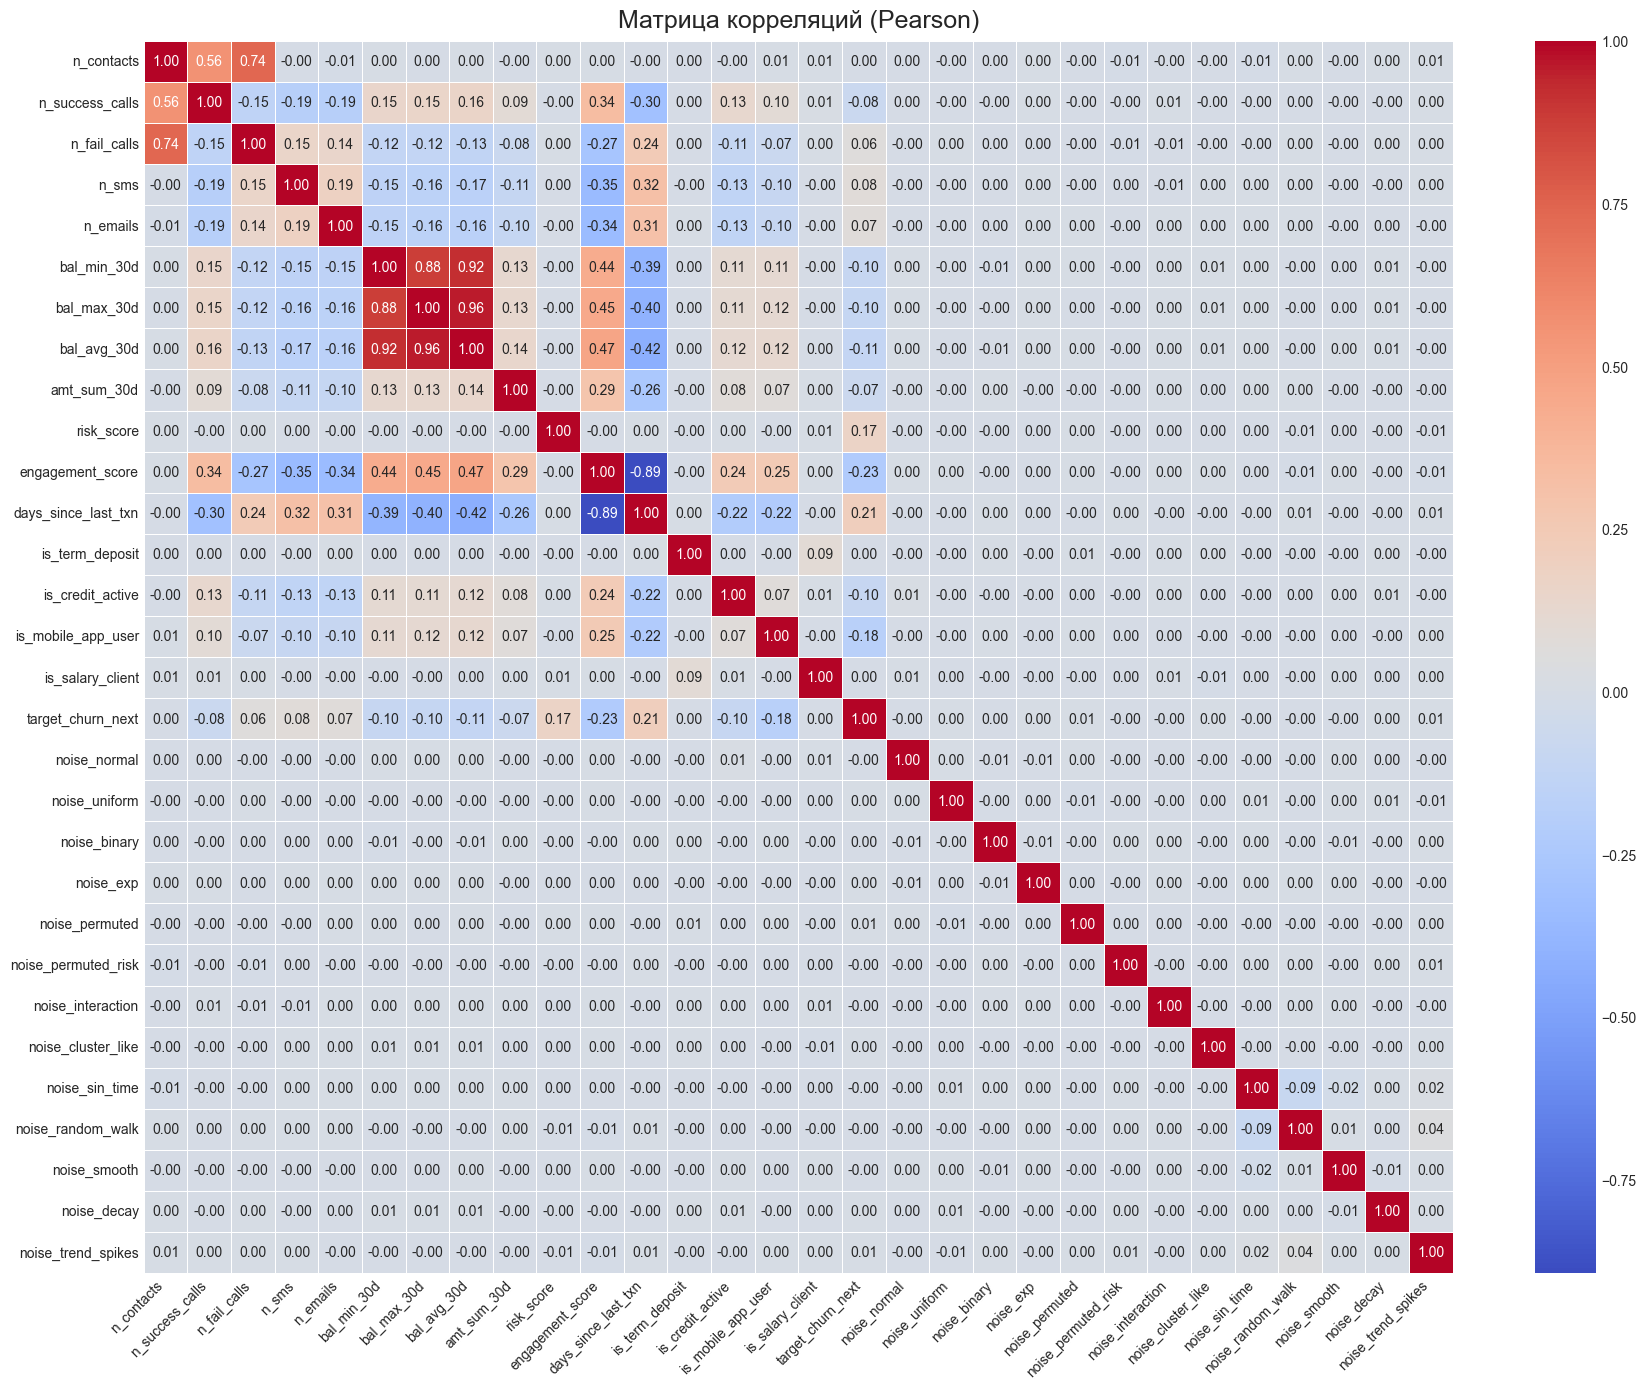

In [9]:
# Матрица обычных корреляций (Pearson) по числовым признакам
numeric_corr = df.drop(['snapshot_month', 'client_id'], axis=1).corr()

plt.figure(figsize=(18, 14), dpi=100)
sns.heatmap(
    numeric_corr,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 10},
    cmap="coolwarm",
    linecolor="white",
    linewidths=0.5,
)
plt.title("Матрица корреляций (Pearson)", fontsize=18, pad=10)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


Достаточно неплохо видно шумные фичи, но у такого подхода есть несколько серьёзных минусов:

- При большом количестве признаков (что в реальных задачах случается постоянно) такая матрица превращается в «ковёр», который сложно интерпретировать.
- Часто приходится жёстко отсекать признаки по порогу корреляции (например, |corr| > 0.7), и это может:
  - не решить проблему многоколлинеарности до конца;
  - **случайно удалить действительно полезные признаки**.
- Классическая корреляция не учитывает скрытые/нелинейные зависимости.
- Она не работает напрямую с категориальными признаками — их нужно предварительно аккуратно кодировать.

Чтобы обойти часть этих ограничений, используют, например, матрицу **Phik**, которая:
- умеет работать и с числовыми, и с категориальными признаками;
- более устойчива к дисбалансу классов и сложным зависимостям.

Есть усовершенствованный вариант корреляционной матрицы - **матрица Phik**

*Документация Phik: https://phik.readthedocs.io/*

interval columns not set, guessing: ['n_contacts', 'n_success_calls', 'n_fail_calls', 'n_sms', 'n_emails', 'bal_min_30d', 'bal_max_30d', 'bal_avg_30d', 'amt_sum_30d', 'risk_score', 'engagement_score', 'days_since_last_txn', 'is_term_deposit', 'is_credit_active', 'is_mobile_app_user', 'is_salary_client', 'target_churn_next', 'noise_normal', 'noise_uniform', 'noise_binary', 'noise_exp', 'noise_permuted', 'noise_permuted_risk', 'noise_interaction', 'noise_cluster_like', 'noise_sin_time', 'noise_random_walk', 'noise_smooth', 'noise_decay', 'noise_trend_spikes']


<Figure size 1600x900 with 0 Axes>

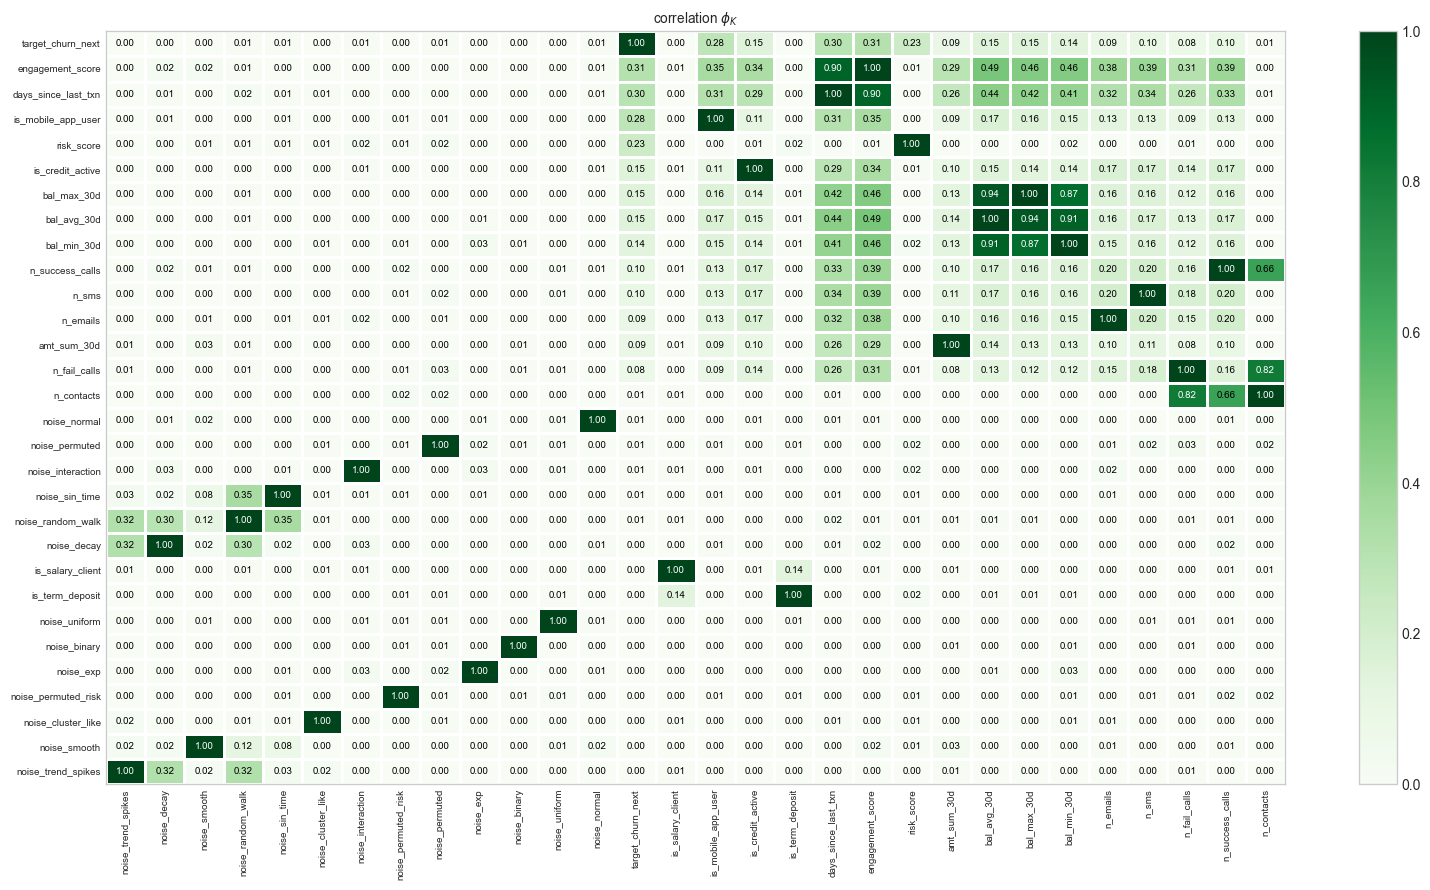

In [10]:
# Матрица φ_K (Phik). Позволяет работать и с числовыми, и с категориальными признаками.

phik_overview = (
    df.drop(['snapshot_month', 'client_id'], axis=1)
      .phik_matrix()
      .round(2)
      .sort_values('target_churn_next')
)

plt.figure(figsize=(16, 9))
plot_correlation_matrix(
    phik_overview.values,
    x_labels=phik_overview.columns,
    y_labels=phik_overview.index,
    vmin=0,
    vmax=1,
    color_map="Greens",
    title=r"correlation $\phi_K$",
    fontsize_factor=0.7,
    figsize=(16, 9),
)
plt.tight_layout()
plt.show()

Несмотря на то, что матрица φ<sub>K</sub> уже умеет:
- работать с категориальными признаками;
- частично ловить нелинейные зависимости,

у неё всё равно есть ограничения:
- она остаётся **глобальной** метрикой связи (не видит локальных эффектов и взаимодействий признаков);
- не даёт прямого ответа, как изменится качество **конкретной модели**, если удалить тот или иной признак.

Поэтому в реальных проектах статистические методы обычно используют как **первый быстрый фильтр**, а затем подключают модель‑зависимые методы важности признаков.



## Методы важности признаков, требующие обучение модели

Теперь перейдём к методам, которые используют уже **обученную модель**:
- `feature_importance` (встроенная важность признаков для деревьев/бустинга);
- permutation importance (перестановочная важность);
- SHAP‑значения.

Плюс таких методов в том, что они:
- учитывают форму решающей поверхности конкретной модели;
- могут работать с большим числом признаков;
- хорошо сочетаются с деревьями решений и градиентным бустингом.

Минус — их нужно считать **после обучения модели**, а значит, они зависят от её настроек и качества.

Документация:
- CatBoost feature importance: https://catboost.ai/en/docs/concepts/fstr
- Permutation importance (`sklearn.inspection.permutation_importance`): https://scikit-learn.org/stable/modules/permutation_importance.html
- SHAP: https://shap.readthedocs.io/


## Feature importance

В прошлом степе мы уже сталкивались с важностью признаков в моделях на деревьях. В CatBoost (и других бустингах) `feature_importance` показывает, насколько часто и насколько «сильно» признак используется в деревьях.

Интуитивно можно думать так: чем выше важность признака, тем больше вклад он вносит в качество модели (с точки зрения количества и «смысла» разбиений в узлах деревьев).

Однако важно помнить:
- классический `feature_importance` может переоценивать признаки с большим количеством возможных разбиений;
- он не всегда корректно отражает важность признаков, которые взаимодействуют друг с другом;
- поэтому его лучше использовать **вместе** с другими методами (permutation importance, SHAP).

В прошлом степе мы как раз сталкнулись с методом `feature_importance()`. Этот метод встречается в древесных моделях, включая бустинги и говорит о важности признаков, с точки зрения "количество разбиений данного признака в узлах дерева"

In [11]:
# Сплит на train / val / OOT

cols_to_drop = ['snapshot_month', 'client_id', 'target_churn_next']
target_col = 'target_churn_next'

# Приводим срез к типу datetime
df['snapshot_month'] = pd.to_datetime(df['snapshot_month'])

# Разделяем по квантилям времени (60% / 20% / 20%)
q60 = df['snapshot_month'].quantile(0.60)
q80 = df['snapshot_month'].quantile(0.80)

train_df = df[df['snapshot_month'] <= q60].copy()
val_df   = df[(df['snapshot_month'] > q60) & (df['snapshot_month'] <= q80)].copy()
oot_df   = df[df['snapshot_month'] > q80].copy()

# Формируем матрицы признаков и целевые переменные
X_train = train_df.drop(cols_to_drop, axis=1)
y_train = train_df[target_col]

X_val = val_df.drop(cols_to_drop, axis=1)
y_val = val_df[target_col]

X_oot = oot_df.drop(cols_to_drop, axis=1)
y_oot = oot_df[target_col]

# Оборачиваем в Pool (CatBoost-формат)
train_pool = Pool(X_train, label=y_train)
val_pool   = Pool(X_val,   label=y_val)
oot_pool   = Pool(X_oot,   label=y_oot)


# Baseline-модель CatBoost

cb_baseline = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

cb_baseline.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
)

# Оценим качество на всех выборках
def evaluate_model(model, train_pool, val_pool, oot_pool, title=""):
    train_proba = model.predict_proba(train_pool)[:, 1]
    val_proba   = model.predict_proba(val_pool)[:, 1]
    oot_proba   = model.predict_proba(oot_pool)[:, 1]

    y_train = train_pool.get_label()
    y_val   = val_pool.get_label()
    y_oot   = oot_pool.get_label()

    roc_train = roc_auc_score(y_train, train_proba)
    roc_val   = roc_auc_score(y_val,   val_proba)
    roc_oot   = roc_auc_score(y_oot,   oot_proba)

    if title:
        print(title)
    print("ROC AUC:")
    print(f"  train: {roc_train:.6f}")
    print(f"  val:   {roc_val:.6f}")
    print(f"  oot:   {roc_oot:.6f}")

evaluate_model(cb_baseline, train_pool, val_pool, oot_pool, title="Baseline CatBoost (все признаки)")

Baseline CatBoost (все признаки)
ROC AUC:
  train: 0.869471
  val:   0.856429
  oot:   0.828966


,Feature Id,Importances
0,risk_score,32.767891
1,engagement_score,23.637782
2,is_mobile_app_user,13.642581
3,days_since_last_txn,8.284311
4,is_credit_active,4.791043
5,bal_max_30d,1.743334
6,bal_avg_30d,1.427233
7,noise_trend_spikes,1.141152
8,noise_exp,1.139746
9,noise_smooth,1.060389


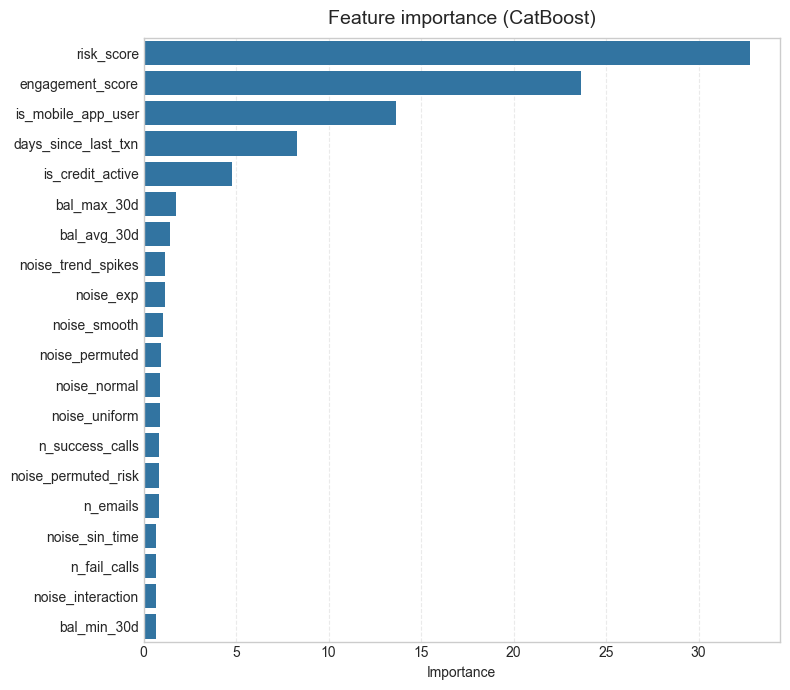

In [12]:
# Важность признаков по версии CatBoost
# Документация: https://catboost.ai/en/docs/concepts/fstr

fi = cb_baseline.get_feature_importance(prettified=True)
fi = fi.sort_values("Importances", ascending=False).reset_index(drop=True)

display(fi.head(20))

plt.figure(figsize=(8, 7))
sns.barplot(
    data=fi.head(20),
    x="Importances",
    y="Feature Id",
    orient="h",
)
plt.title("Feature importance (CatBoost)", fontsize=14, pad=10)
plt.xlabel("Importance")
plt.ylabel("")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Permutation importance
Permutation importance (перестановочная важность) показывает, **насколько ухудшается качество модели**, если перемешать значения одного признака.

Идея простая:
- если признак важный -> перемешивание разрушает информацию -> качество падает;
- если непринципиальный -> перемешивание ничего не меняет.

**Плюсы:**
- учитывает форму зависимости, которую изучила конкретная модель;
- работает и с линейными, и с нелинейными моделями;
- проще интерпретировать, чем raw feature_importance.

**Минусы:**
- считается медленно (нужно много перестановок);
- чувствителен к мультиколлинеарности: если признаки дублируют друг друга — важность размазывается.

**Как читать график:**
- длинная горизонтальная линия -> сильное падение качества -> важный признак;
- короткая линия -> признак почти ничего не даёт.


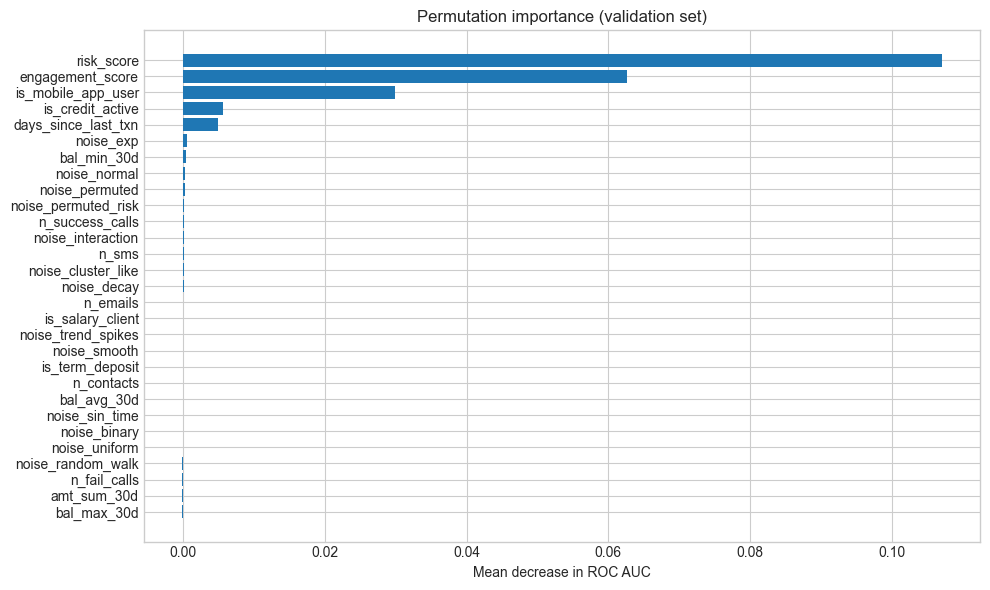

In [13]:
# Перестановочная важность признаков
# Документация: https://scikit-learn.org/stable/modules/permutation_importance.html

# Важно: по умолчанию sklearn для классификаторов использует accuracy.
# Для задач churn нам интереснее ROC-AUC, поэтому явно укажем scoring="roc_auc".
perm = permutation_importance(
    cb_baseline,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

sorted_idx = perm.importances_mean.argsort()
sorted_features = np.array(X_val.columns)[sorted_idx]

plt.figure(figsize=(10, 6))
plt.barh(range(len(sorted_idx)), perm.importances_mean[sorted_idx])
plt.yticks(range(len(sorted_idx)), sorted_features)
plt.title("Permutation importance (validation set)")
plt.xlabel("Mean decrease in ROC AUC")
plt.tight_layout()
plt.show()


## SHAP

SHAP основан на **значениях Шэпли** из теории игр: модельное предсказание раскладывается на вклады признаков.

**Что даёт SHAP:**
- показывает вклад каждого признака в конкретное предсказание;
- ловит нелинейные зависимости и взаимодействия;
- даёт честную картину важности по сравнению с обычным feature_importance.

**Mean |SHAP| plot:**
- большие значения -> признак стабильно влияет на предсказание;
- маленькие -> влияние слабое.

**Плюсы:**
- интерпретируемо;
- устойчиво к мультиколлинеарности;
- CatBoost считает SHAP очень быстро.

**Минусы:**
- для больших датасетов вне CatBoost может быть медленным.


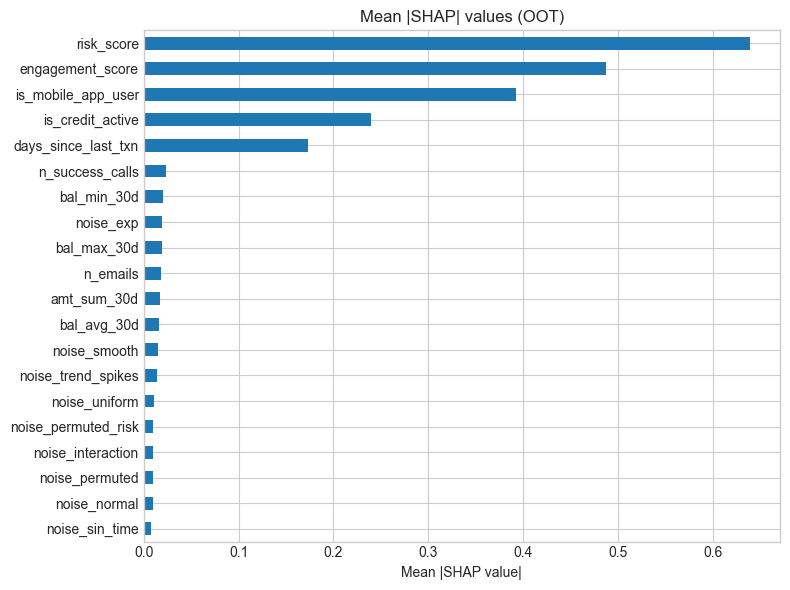

In [14]:
# SHAP-значения через CatBoost
# Документация: https://catboost.ai/en/docs/concepts/shap-values

# Получаем матрицу SHAP-значений для OOT-выборки
shap_values = cb_baseline.get_feature_importance(
    data=oot_pool,
    type="ShapValues",
)

# В ShapValues последняя колонка — base_value (сдвиг)
shap_df = pd.DataFrame(
    shap_values,
    columns=list(X_oot.columns) + ["base_value"],
)

# Средние абсолютные SHAP по признакам
mean_abs_shap = (
    shap_df[X_oot.columns]
    .abs()
    .mean()
    .sort_values(ascending=True)
)

mean_abs_shap.tail(20).plot(
    kind="barh",
    figsize=(8, 6),
    title="Mean |SHAP| values (OOT)",
)
plt.xlabel("Mean |SHAP value|")
plt.tight_layout()
plt.show()


## Обучение на самых важных признаках

In [15]:
# Объединим информацию о важности из CatBoost FI и SHAP

fi_simple = cb_baseline.get_feature_importance(prettified=True)
fi_simple = fi_simple.set_index("Feature Id")["Importances"]

shap_values = cb_baseline.get_feature_importance(
    data=oot_pool,
    type="ShapValues",
)
shap_df = pd.DataFrame(
    shap_values,
    columns=list(X_oot.columns) + ["base_value"],
)
mean_abs_shap = shap_df[X_oot.columns].abs().mean()

perm_series = pd.Series(
    perm.importances_mean,
    index=X_val.columns
)

# Собираем в один датафрейм
all_importances = pd.DataFrame({
    "CatBoost": fi_simple,
    "SHAP": mean_abs_shap,
    "Permutation": perm_series,
})


# Нормируем каждую метрику на свой максимум
all_importances["CatBoost"] = all_importances["CatBoost"] / all_importances["CatBoost"].max()
all_importances["SHAP"] = all_importances["SHAP"] / all_importances["SHAP"].max()
all_importances["Permutation"] = all_importances["Permutation"] / all_importances["Permutation"].max()

# Средняя важность по трём методам
all_importances["mean_importance"] = all_importances[["CatBoost", "SHAP", "Permutation"]].mean(axis=1)

# Сортируем
all_importances = all_importances.sort_values("mean_importance", ascending=False)
display(all_importances.head(20))

# Топ-8 признаков
used_features = list(all_importances.head(8).index)
print("Топ-8 признаков:", used_features)


,CatBoost,SHAP,Permutation,mean_importance
risk_score,1.000000,1.000000,1.000000,1.000000
engagement_score,0.721370,0.763203,0.584959,0.689844
is_mobile_app_user,0.416340,0.614775,0.279247,0.436787
is_credit_active,0.146212,0.374275,0.051856,0.190781
days_since_last_txn,0.252818,0.271298,0.046318,0.190144
bal_max_30d,0.053202,0.029839,-0.001910,0.027044
noise_exp,0.034782,0.029910,0.004687,0.023127
bal_avg_30d,0.043556,0.025768,-0.000167,0.023052
n_success_calls,0.026002,0.036336,0.001341,0.021226
noise_smooth,0.032361,0.024354,0.000053,0.018923


Топ-8 признаков: ['risk_score', 'engagement_score', 'is_mobile_app_user', 'is_credit_active', 'days_since_last_txn', 'bal_max_30d', 'noise_exp', 'bal_avg_30d']


In [16]:
# Обучим модель только на топ-8 признаках

X_train_top8 = X_train[used_features]
X_val_top8   = X_val[used_features]
X_oot_top8   = X_oot[used_features]

train_pool_top8 = Pool(X_train_top8, label=y_train)
val_pool_top8   = Pool(X_val_top8,   label=y_val)
oot_pool_top8   = Pool(X_oot_top8,   label=y_oot)

cb_top8 = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

cb_top8.fit(
    train_pool_top8,
    eval_set=val_pool_top8,
    use_best_model=True,
)

evaluate_model(cb_top8, train_pool_top8, val_pool_top8, oot_pool_top8, title="CatBoost (только топ-8 признаков)")


CatBoost (только топ-8 признаков)
ROC AUC:
  train: 0.862689
  val:   0.857519
  oot:   0.828388


In [17]:
# Baseline CatBoost (все признаки)
# ROC AUC:
#   train: 0.862983
#   val:   0.856788
#   oot:   0.828646

То есть, мы немного, но улучшили метрику на OOT, оставив при этом всего 8 признаков вместо 29 изначальных! При этом мы отбросили не только шумные признаки.
Хотелось бы не отсекать признаки сразу топором, а как-то более тонко подходить к отбору. Для этого сущесвуют различные алгоритмы по отбору признаков

## Forward Selection

Ещё один популярный подход — пошаговый отбор признаков (forward selection). Идея простая:

1. Начинаем с **пустого** набора признаков.
2. На каждом шаге:
   - перебираем все ещё не добавленные признаки;
   - для каждого считаем качество модели (например, ROC‑AUC на валидации);
   - выбираем тот, который даёт лучший прирост метрики.
3. Повторяем, пока:
   - не достигнем нужного числа признаков;
   - или качество перестанет заметно расти.

Таким образом мы строим **компактный, но сильный** поднабор признаков, ориентируясь на метрику качества.

Минусы:
- при большом числе признаков и сложной модели метод становится вычислительно дорогим;
- возможны локальные оптимумы (не всегда находим глобально оптимальный набор).

In [18]:
from typing import List, Callable, Tuple
import pandas as pd

def forward_feature_selection(
    model: CatBoostClassifier,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_val: pd.DataFrame,
    y_val: pd.Series,
    metric: Callable = roc_auc_score,
    verbose: bool = True,
) -> Tuple[List[str], pd.DataFrame]:
    """Простой forward selection по одному признаку.

    На каждом шаге:
    - перебираем все ещё не выбранные признаки;
    - обучаем модель;
    - считаем качество на валидации;
    - добавляем признак с максимальным приростом метрики.
    """

    remaining_features = list(X_train.columns)
    selected_features: List[str] = []
    history = []

    best_score = None

    step = 0
    while len(remaining_features) > 0:
        step += 1
        scores = []

        for feat in remaining_features:
            current_features = selected_features + [feat]

            train_pool_fs = Pool(X_train[current_features], label=y_train)
            val_pool_fs   = Pool(X_val[current_features],   label=y_val)

            model_fs = CatBoostClassifier(**model.get_params())

            model_fs.fit(
                train_pool_fs,
                eval_set=val_pool_fs,
                use_best_model=True,
                verbose=False,
            )

            val_proba = model_fs.predict_proba(val_pool_fs)[:, 1]
            score = metric(y_val, val_proba)
            scores.append((feat, score))

        # выбираем признак с максимальным скором
        best_feat, best_feat_score = max(scores, key=lambda x: x[1])

        if best_score is None or best_feat_score > best_score:
            best_score = best_feat_score
            selected_features.append(best_feat)
            remaining_features.remove(best_feat)

            history.append({
                "step": step,
                "added_feature": best_feat,
                "val_score": best_feat_score,
            })

            if verbose:
                print(f"[step {step}] added: {best_feat}, val {best_feat_score:.4f}")

        else:
            if verbose:
                print(f"[step {step}] no improvement, stop")
            break

    history_df = pd.DataFrame(history)
    return selected_features, history_df


In [19]:
# Запускаем forward selection на том же сплите train / val
base_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=50,
    random_state=42,
    verbose=False,
)

selected_features_fs, history_fs = forward_feature_selection(
    base_model,
    X_train,
    y_train,
    X_val,
    y_val,
    metric=roc_auc_score,
    verbose=True,
)

print("\nЛучшие признаки (forward selection):", selected_features_fs)
history_fs.head()

[step 1] added: engagement_score, val 0.7750
[step 2] added: risk_score, val 0.8373
[step 3] added: is_mobile_app_user, val 0.8549
[step 4] added: is_credit_active, val 0.8554
[step 5] added: noise_trend_spikes, val 0.8571
[step 6] added: noise_interaction, val 0.8574
[step 7] added: days_since_last_txn, val 0.8575
[step 8] added: noise_permuted_risk, val 0.8590
[step 9] no improvement, stop

Лучшие признаки (forward selection): ['engagement_score', 'risk_score', 'is_mobile_app_user', 'is_credit_active', 'noise_trend_spikes', 'noise_interaction', 'days_since_last_txn', 'noise_permuted_risk']


,step,added_feature,val_score
0,1,engagement_score,0.775010
1,2,risk_score,0.837254
2,3,is_mobile_app_user,0.854915
3,4,is_credit_active,0.855383
4,5,noise_trend_spikes,0.857117


In [20]:
# Обучим модель на признаках, отобранных forward selection, и сравним качество

X_train_fs = X_train[selected_features_fs]
X_val_fs   = X_val[selected_features_fs]
X_oot_fs   = X_oot[selected_features_fs]

train_pool_fs = Pool(X_train_fs, label=y_train)
val_pool_fs   = Pool(X_val_fs,   label=y_val)
oot_pool_fs   = Pool(X_oot_fs,   label=y_oot)

model_fs = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

model_fs.fit(
    train_pool_fs,
    eval_set=val_pool_fs,
    use_best_model=True,
)

evaluate_model(model_fs, train_pool_fs, val_pool_fs, oot_pool_fs, title="CatBoost (forward selection)")


CatBoost (forward selection)
ROC AUC:
  train: 0.864995
  val:   0.857618
  oot:   0.829069


In [21]:
# Baseline CatBoost (все признаки)
# ROC AUC:
#   train: 0.862983
#   val:   0.856788
#   oot:   0.828646

### Backward selection (идея для расширения)

В этом ноутбуке мы реализовали forward selection, но полезно знать и обратный подход — **backward selection**:

- начинаем **со всех признаков**;
- на каждом шаге пытаемся удалить по одному признаку;
- выбираем удаление, при котором качество падает минимально (или даже чуть растёт);
- повторяем, пока не останется нужное количество признаков.

На практике:
- backward selection хорошо работает, когда признаков не очень много;
- часто его комбинируют с регуляризацией и встроенной важностью признаков.

Если хотите прокачаться, можно реализовать backward selection как дополнительное упражнение к этому ноутбуку.

***Отправляйте свою реализацию backward selection в комментарии к этому уроку - самая лучшая реализация войдет в этот ноутбук!***

Ниже решение ученика Anonymous 627006720

In [22]:
from typing import Callable, List, Tuple

def backward_feature_selection(
    model: CatBoostClassifier,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_val: pd.DataFrame,
    y_val: pd.Series,
    remaining_features_count: int,
    metric: Callable = roc_auc_score,
    verbose: bool = True,
) -> Tuple[List[str], pd.DataFrame]:

    def get_model_score(current_features: list) -> float:
        train_pool_fs = Pool(X_train[current_features], label=y_train)
        val_pool_fs   = Pool(X_val[current_features],   label=y_val)

        model_fs = CatBoostClassifier(**model.get_params())

        model_fs.fit(
            train_pool_fs,
            eval_set=val_pool_fs,
            use_best_model=True,
            verbose=False,
        )

        val_proba = model_fs.predict_proba(val_pool_fs)[:, 1]
        score = metric(y_val, val_proba)

        return score


    remaining_features = list(X_train.columns)
    removing_features: List[str] = []
    history = []

    last_score = get_model_score(remaining_features)

    step = 0

    while len(remaining_features) > remaining_features_count:
        step += 1

        scores = []

        for feat in remaining_features:
            current_features = [item for item in remaining_features if item != feat]

            score = get_model_score(current_features)

            diff_score = last_score - score
            scores.append((feat, score, diff_score))

        removable_feat, last_feat_score, min_diff_score = min(scores, key=lambda x: x[2])

        last_score = last_feat_score
        remaining_features.remove(removable_feat)
        removing_features.append(removable_feat)

        history.append({
            "step": step,
            "removing_feature": removable_feat,
            "val_score": last_feat_score,
        })

        if verbose:
            print(f"[step {step}] removing: {removable_feat}, val {last_feat_score:.4f}")

    history_df = pd.DataFrame(history)

    return remaining_features, history_df

In [23]:
bw_cb = CatBoostClassifier(
    iterations=300,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=40,
    random_state=42,
    verbose=False,
)

remaining_features, history_df = backward_feature_selection(
    model=bw_cb,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    remaining_features_count=10,
)

[step 1] removing: bal_max_30d, val 0.8585
[step 2] removing: n_contacts, val 0.8579
[step 3] removing: bal_avg_30d, val 0.8587
[step 4] removing: n_success_calls, val 0.8583
[step 5] removing: n_fail_calls, val 0.8582
[step 6] removing: noise_smooth, val 0.8589
[step 7] removing: noise_sin_time, val 0.8572
[step 8] removing: noise_interaction, val 0.8590
[step 9] removing: noise_binary, val 0.8578
[step 10] removing: is_salary_client, val 0.8584
[step 11] removing: is_term_deposit, val 0.8578
[step 12] removing: noise_random_walk, val 0.8589
[step 13] removing: noise_permuted, val 0.8587
[step 14] removing: amt_sum_30d, val 0.8587
[step 15] removing: noise_decay, val 0.8579
[step 16] removing: noise_cluster_like, val 0.8579
[step 17] removing: bal_min_30d, val 0.8582
[step 18] removing: n_emails, val 0.8579
[step 19] removing: noise_uniform, val 0.8591


In [24]:
# Обучим модель на признаках, отобранных backward selection, и сравним качество

X_train_bw = X_train[remaining_features]
X_val_bw  = X_val[remaining_features]
X_oot_bw   = X_oot[remaining_features]

train_pool_bw = Pool(X_train_bw, label=y_train)
val_pool_bw   = Pool(X_val_bw,   label=y_val)
oot_pool_bw   = Pool(X_oot_bw,   label=y_oot)

model_bw = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

model_bw.fit(
    train_pool_bw,
    eval_set=val_pool_bw,
    use_best_model=True,
)

evaluate_model(model_bw, train_pool_bw, val_pool_bw, oot_pool_bw, title="CatBoost (backward selection)")

CatBoost (backward selection)
ROC AUC:
  train: 0.863309
  val:   0.859268
  oot:   0.827351


## CatBoost `select_features`

CatBoost умеет сам отбирать признаки с помощью метода [`select_features`](https://catboost.ai/en/docs/concepts/python-reference_catboostclassifier_select_features).

Основные идеи:
- модель обучается многократно на разных поднаборах признаков;
- на основе изменения метрики качества (AUC, Logloss и т.д.) CatBoost выбирает наиболее важные признаки;
- есть разные алгоритмы отбора, в том числе основанные на SHAP‑значениях (`RecursiveByShapValues`).

Плюсы:
- можно быстро построить компактный набор признаков «из коробки»;
- не нужно вручную реализовывать forward/backward selection;
- удобно для прототипирования.

Минусы:
- нужно задавать конечное количество признаков и шагов
- метод может быть тяжёлым по времени на больших датасетах;
- результат всё равно стоит интерпретировать и проверять дополнительно (например, через permutation importance или SHAP).

In [25]:
# Отбор признаков с помощью CatBoost `select_features`
# Документация: https://catboost.ai/en/docs/concepts/python-reference_catboostclassifier_select_features

select_model = CatBoostClassifier(
    iterations=1500,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

select_result = select_model.select_features(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    features_for_select=list(X_train.columns),
    num_features_to_select=13,
    steps=7,
    algorithm="RecursiveByShapValues",
    shap_calc_type="Regular",
    verbose=False,
)

selected_cf = select_result["selected_features_names"]
print("Выбранные признаки CatBoost select_features:", selected_cf)


Learning rate set to 0.07593
Step #1 out of 7
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8577239024
bestIteration = 92

Shrink model to first 93 iterations.
Feature #4 eliminated
Feature #2 eliminated
Feature #26 eliminated
Step #2 out of 7
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8570911322
bestIteration = 82

Shrink model to first 83 iterations.
Feature #20 eliminated
Feature #7 eliminated
Feature #17 eliminated
Step #3 out of 7
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8581426473
bestIteration = 99

Shrink model to first 100 iterations.
Feature #25 eliminated
Feature #6 eliminated
Step #4 out of 7
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8572208966
bestIteration = 97

Shrink model to first 98 iterations.
Feature #8 eliminated
Feature #22 eliminated
Feature #27 eliminated
Step #5 out of 7
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8592203108
bestItera

In [26]:
# Оценим качество модели, обученной только на признаках, выбранных select_features

X_train_cf = X_train[selected_cf]
X_val_cf   = X_val[selected_cf]
X_oot_cf   = X_oot[selected_cf]

train_pool_cf = Pool(X_train_cf, label=y_train)
val_pool_cf   = Pool(X_val_cf,   label=y_val)
oot_pool_cf   = Pool(X_oot_cf,   label=y_oot)

model_cf = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

model_cf.fit(
    train_pool_cf,
    eval_set=val_pool_cf,
    use_best_model=True,
)

evaluate_model(model_cf, train_pool_cf, val_pool_cf, oot_pool_cf, title="CatBoost (признаки из select_features)")


CatBoost (признаки из select_features)
ROC AUC:
  train: 0.875790
  val:   0.858285
  oot:   0.827599


In [27]:
# Baseline CatBoost (все признаки)
# ROC AUC:
#   train: 0.862983
#   val:   0.856788
#   oot:   0.828646

### Домашнее задание

У вас есть отдельный датасет:

- всего **200 признаков**;
- только **10 из них действительно информативные**, остальные — шум.

**Ваша задача:**

1. Загрузить датасет (`data.csv`) из ячейки ниже.
2. Выбрать и реализовать **любую стратегию отбора признаков** из урока (или комбинацию методов), например:
   - фильтрационные методы (корреляция / Phik);
   - `feature_importance` CatBoost;
   - permutation importance;
   - SHAP‑значения;
   - `CatBoostClassifier.select_features`.
   - Forward Selection
   - Самописный Backward Selection
   - Комбинацию методов
3. Отобрать **ровно 10 признаков**, которые лучше всего объясняют таргет.
4. На Stepik в качестве ответа ввести **список названий признаков** в формате Python‑списка, например:

```python
print(['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5',
 'feature_196', 'feature_197', 'feature_198', 'feature_199', 'feature_200'])
```

> Важно: порядок признаков в списке не играет роли, но сами названия должны быть указаны **точно так же, как в датасете**.

---


In [28]:
# # Датасет для домашнего задания
# # Здесь 200 признаков, из которых только 10 информативные

# # !pip install -q gdown

# file_id = "1OxO8Hconm-3GzZ3F59H1wffQP7TWWL_C"
# url = f"https://drive.google.com/uc?id={file_id}"

# import gdown
# gdown.download(url, "data.csv", quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1OxO8Hconm-3GzZ3F59H1wffQP7TWWL_C
From (redirected): https://drive.google.com/uc?id=1OxO8Hconm-3GzZ3F59H1wffQP7TWWL_C&confirm=t&uuid=debb747e-d717-4afc-9d0f-01ae837e5cbd
To: c:\Projects\ds-stepik\ds_simulation\data.csv
100%|██████████| 117M/117M [00:14<00:00, 7.97MB/s] 


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_192,feature_193,feature_194,feature_195,feature_196,feature_197,feature_198,feature_199,feature_200,target
0,0.496714,-0.138264,0.647689,1.523030,0.817131,-0.234137,1.579213,0.767435,-0.469474,0.542560,...,0.856399,0.214094,-1.245739,0.173181,0.385317,-0.883857,0.153725,0.058209,-1.142970,1
1,0.357787,0.560785,1.083051,1.053802,-1.017189,-0.937825,0.515035,0.513786,0.515048,3.852731,...,0.491919,-1.320233,1.831459,1.179440,-0.469176,-1.713135,1.353872,-0.114540,1.237816,1
2,-1.594428,-0.599375,0.005244,0.046981,-0.536024,0.622850,-1.067620,-0.142379,0.120296,0.514439,...,-0.477657,0.478980,0.333662,1.037540,-0.510016,-0.269875,-0.978764,-0.444293,0.377300,0
3,0.756989,-0.922165,0.869606,1.355638,-0.435437,1.876796,-0.773789,-1.244655,-1.778720,1.496044,...,0.207688,0.271579,-1.276749,-1.081057,1.053153,-0.039555,0.681501,0.028318,0.029756,0
4,0.938284,-0.516045,0.096121,-0.462275,-0.803002,-0.309172,0.222134,-0.478749,1.255756,-0.894607,...,-2.041735,-0.247177,-0.681984,-1.001620,-0.281100,1.797687,0.640843,-0.571179,0.572583,1


In [30]:
import os
import gdown

# Скачивание

FILE_ID = '1OxO8Hconm-3GzZ3F59H1wffQP7TWWL_C'
FOLDER = 'content'
PATH = os.path.join(FOLDER, 'data.csv')

# Проверка наличия файла и скачивание по необходимости
if not os.path.exists(PATH):
    gdown.download(f'https://drive.google.com/uc?id={FILE_ID}', PATH, quiet=True)
    print('Файл скачан:', PATH)
else:
    print('Файл уже скачан')

Файл скачан: content\data.csv


In [31]:
df_hw = pd.read_csv("content/data.csv")
df_hw.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_192,feature_193,feature_194,feature_195,feature_196,feature_197,feature_198,feature_199,feature_200,target
0,0.496714,-0.138264,0.647689,1.523030,0.817131,-0.234137,1.579213,0.767435,-0.469474,0.542560,...,0.856399,0.214094,-1.245739,0.173181,0.385317,-0.883857,0.153725,0.058209,-1.142970,1
1,0.357787,0.560785,1.083051,1.053802,-1.017189,-0.937825,0.515035,0.513786,0.515048,3.852731,...,0.491919,-1.320233,1.831459,1.179440,-0.469176,-1.713135,1.353872,-0.114540,1.237816,1
2,-1.594428,-0.599375,0.005244,0.046981,-0.536024,0.622850,-1.067620,-0.142379,0.120296,0.514439,...,-0.477657,0.478980,0.333662,1.037540,-0.510016,-0.269875,-0.978764,-0.444293,0.377300,0
3,0.756989,-0.922165,0.869606,1.355638,-0.435437,1.876796,-0.773789,-1.244655,-1.778720,1.496044,...,0.207688,0.271579,-1.276749,-1.081057,1.053153,-0.039555,0.681501,0.028318,0.029756,0
4,0.938284,-0.516045,0.096121,-0.462275,-0.803002,-0.309172,0.222134,-0.478749,1.255756,-0.894607,...,-2.041735,-0.247177,-0.681984,-1.001620,-0.281100,1.797687,0.640843,-0.571179,0.572583,1


In [34]:
# Ваш код
from sklearn.model_selection import train_test_split

In [45]:
X = df_hw.drop('target', axis=1)
y = df_hw['target']

In [46]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, train_size=0.6, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [47]:
train_pool = Pool(X_train, label=y_train)
val_pool   = Pool(X_val,   label=y_val)
test_pool  = Pool(X_test,  label=y_test)

In [48]:
# Baseline-модель CatBoost

cb_baseline = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

cb_baseline.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
)

# Оценим качество на всех выборках
def evaluate_model(model, train_pool, val_pool, test_pool, title=""):
    train_proba = model.predict_proba(train_pool)[:, 1]
    val_proba   = model.predict_proba(val_pool)[:, 1]
    oot_proba   = model.predict_proba(test_pool)[:, 1]

    y_train = train_pool.get_label()
    y_val   = val_pool.get_label()
    y_oot   = test_pool.get_label()

    roc_train = roc_auc_score(y_train, train_proba)
    roc_val   = roc_auc_score(y_val,   val_proba)
    roc_oot   = roc_auc_score(y_oot,   oot_proba)

    if title:
        print(title)
    print("ROC AUC:")
    print(f"  train: {roc_train:.6f}")
    print(f"  val:   {roc_val:.6f}")
    print(f"  oot:   {roc_oot:.6f}")

evaluate_model(cb_baseline, train_pool, val_pool, test_pool, title="Baseline CatBoost (все признаки)")

Baseline CatBoost (все признаки)
ROC AUC:
  train: 0.949117
  val:   0.916941
  oot:   0.921310


,Feature Id,Importances
0,feature_152,32.210747
1,feature_34,10.892343
2,feature_71,10.303298
3,feature_124,7.029882
4,feature_58,5.776970
5,feature_140,5.693901
6,feature_5,5.236870
7,feature_50,4.219426
8,feature_151,4.213129
9,feature_116,0.588214


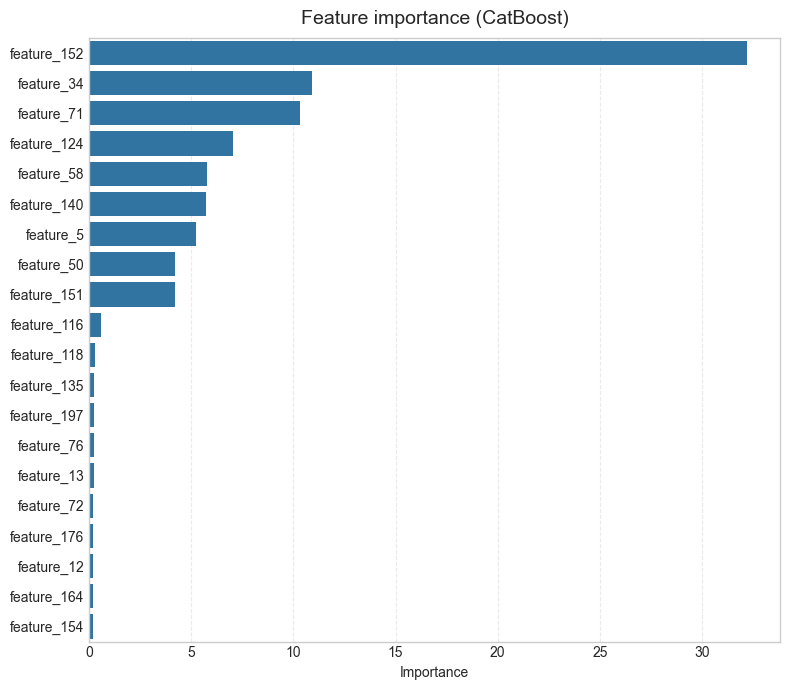

In [49]:
fi = cb_baseline.get_feature_importance(prettified=True)
fi = fi.sort_values("Importances", ascending=False).reset_index(drop=True)

display(fi.head(20))

plt.figure(figsize=(8, 7))
sns.barplot(
    data=fi.head(20),
    x="Importances",
    y="Feature Id",
    orient="h",
)
plt.title("Feature importance (CatBoost)", fontsize=14, pad=10)
plt.xlabel("Importance")
plt.ylabel("")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [54]:
print(fi[:10]['Feature Id'].tolist())

['feature_152', 'feature_34', 'feature_71', 'feature_124', 'feature_58', 'feature_140', 'feature_5', 'feature_50', 'feature_151', 'feature_116']


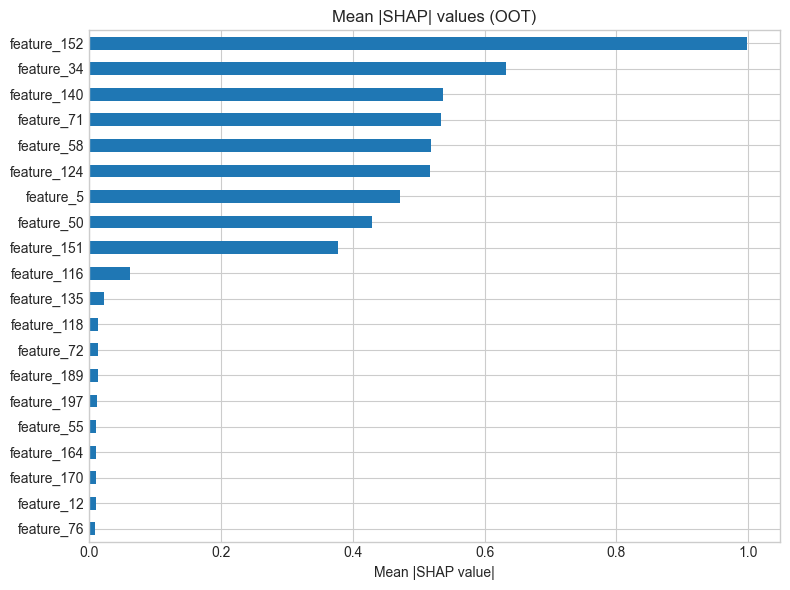

In [61]:
# SHAP-значения через CatBoost
# Документация: https://catboost.ai/en/docs/concepts/shap-values

# Получаем матрицу SHAP-значений для OOT-выборки
shap_values = cb_baseline.get_feature_importance(
    data=test_pool,
    type="ShapValues",
)

# В ShapValues последняя колонка — base_value (сдвиг)
shap_df = pd.DataFrame(
    shap_values,
    columns=list(X_test.columns) + ["base_value"],
)

# Средние абсолютные SHAP по признакам
mean_abs_shap = (
    shap_df[X_test.columns]
    .abs()
    .mean()
    .sort_values(ascending=True)
)

mean_abs_shap.tail(20).plot(
    kind="barh",
    figsize=(8, 6),
    title="Mean |SHAP| values (OOT)",
)
plt.xlabel("Mean |SHAP value|")
plt.tight_layout()
plt.show()

In [62]:
# Отбор признаков с помощью CatBoost `select_features`
# Документация: https://catboost.ai/en/docs/concepts/python-reference_catboostclassifier_select_features

select_model = CatBoostClassifier(
    iterations=1500,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

select_result = select_model.select_features(
    X_train,
    y_train,
    eval_set=(X_val, y_val),
    features_for_select=list(X_train.columns),
    num_features_to_select=13,
    steps=7,
    algorithm="RecursiveByShapValues",
    shap_calc_type="Regular",
    verbose=False,
)

selected_cf = select_result["selected_features_names"]
print("Выбранные признаки CatBoost select_features:", selected_cf)


Learning rate set to 0.054245
Step #1 out of 7
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9159662084
bestIteration = 186

Shrink model to first 187 iterations.
Feature #196 eliminated
Feature #182 eliminated
Feature #54 eliminated
Feature #134 eliminated
Feature #117 eliminated
Feature #140 eliminated
Feature #11 eliminated
Feature #74 eliminated
Feature #1 eliminated
Feature #21 eliminated
Feature #120 eliminated
Feature #164 eliminated
Feature #50 eliminated
Feature #17 eliminated
Feature #100 eliminated
Feature #162 eliminated
Feature #113 eliminated
Feature #53 eliminated
Feature #96 eliminated
Feature #143 eliminated
Feature #155 eliminated
Feature #3 eliminated
Feature #163 eliminated
Feature #169 eliminated
Feature #160 eliminated
Feature #91 eliminated
Feature #145 eliminated
Feature #35 eliminated
Feature #90 eliminated
Feature #136 eliminated
Feature #181 eliminated
Feature #191 eliminated
Feature #9 eliminated
Feature #125 eliminated
Feature #198 el

In [63]:
# Оценим качество модели, обученной только на признаках, выбранных select_features

X_train_cf = X_train[selected_cf]
X_val_cf   = X_val[selected_cf]
X_test_cf   = X_test[selected_cf]

train_pool_cf = Pool(X_train_cf, label=y_train)
val_pool_cf   = Pool(X_val_cf,   label=y_val)
test_pool_cf  = Pool(X_test_cf,   label=y_test)

model_cf = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    early_stopping_rounds=100,
    random_state=42,
    verbose=False,
)

model_cf.fit(
    train_pool_cf,
    eval_set=val_pool_cf,
    use_best_model=True,
)

evaluate_model(model_cf, train_pool_cf, val_pool_cf, test_pool_cf, title="CatBoost (признаки из select_features)")


CatBoost (признаки из select_features)
ROC AUC:
  train: 0.939432
  val:   0.918079
  oot:   0.921133


In [64]:
selected_cf[:10]

['feature_5',
 'feature_13',
 'feature_34',
 'feature_50',
 'feature_58',
 'feature_71',
 'feature_72',
 'feature_116',
 'feature_124',
 'feature_140']